In [1]:
import pandas as pd
import numpy as np

# Load the dataset
file_path = "/content/indian_major_20_banks_fd_rates_10_years.csv"
df = pd.read_csv(file_path)

# Inspect structure and first 5 rows
print("Dataset Shape:", df.shape)
print("\nColumn Info & Data Types:")
print(df.info())
display(df.head())

Dataset Shape: (200, 7)

Column Info & Data Types:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 7 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   Financial_Year                   200 non-null    object 
 1   Bank_Name                        200 non-null    object 
 2   Sector                           200 non-null    object 
 3   1_Year_FD_Rate_Pct               200 non-null    float64
 4   3_Year_FD_Rate_Pct               200 non-null    float64
 5   5_Year_FD_Rate_Pct               200 non-null    float64
 6   Senior_Citizen_Extra_Spread_Pct  200 non-null    float64
dtypes: float64(4), object(3)
memory usage: 11.1+ KB
None


,Financial_Year,Bank_Name,Sector,1_Year_FD_Rate_Pct,3_Year_FD_Rate_Pct,5_Year_FD_Rate_Pct,Senior_Citizen_Extra_Spread_Pct
0,2016-17,State Bank of India,Public,7.00,6.75,6.50,0.5
1,2016-17,Punjab National Bank,Public,7.05,6.80,6.55,0.5
2,2016-17,Bank of Baroda,Public,7.05,6.90,6.55,0.5
3,2016-17,Canara Bank,Public,7.10,6.80,6.60,0.5
4,2016-17,Union Bank of India,Public,7.00,6.75,6.50,0.5


In [2]:
# 1. Check for missing (null) values per column
print("Missing Values per Column:")
print(df.isnull().sum())

# 2. Check for exact duplicate rows or duplicate (Bank_Name, Financial_Year) pairs
print("\nExact Duplicate Rows:", df.duplicated().sum())
print("Duplicate Bank-Year Pairs:", df.duplicated(subset=['Bank_Name', 'Financial_Year']).sum())

# 3. Clean string columns (strip accidental leading/trailing spaces)
for col in ['Financial_Year', 'Bank_Name', 'Sector']:
    df[col] = df[col].astype(str).str.strip()

# 4. Verify unique banks, sectors, and summary statistics
print("\nUnique Banks Count:", df['Bank_Name'].nunique())
print("Sector Breakdown:\n", df['Sector'].value_counts())
print("\nSummary Statistics:")
display(df.describe().round(2))

Missing Values per Column:
Financial_Year                     0
Bank_Name                          0
Sector                             0
1_Year_FD_Rate_Pct                 0
3_Year_FD_Rate_Pct                 0
5_Year_FD_Rate_Pct                 0
Senior_Citizen_Extra_Spread_Pct    0
dtype: int64

Exact Duplicate Rows: 0
Duplicate Bank-Year Pairs: 0

Unique Banks Count: 20
Sector Breakdown:
 Sector
Public     100
Private    100
Name: count, dtype: int64

Summary Statistics:


,1_Year_FD_Rate_Pct,3_Year_FD_Rate_Pct,5_Year_FD_Rate_Pct,Senior_Citizen_Extra_Spread_Pct
count,200.00,200.00,200.00,200.0
mean,6.50,6.49,6.35,0.5
std,0.73,0.64,0.49,0.0
min,4.90,5.15,5.25,0.5
25%,6.10,6.09,6.09,0.5
50%,6.70,6.70,6.50,0.5
75%,6.95,6.95,6.70,0.5
max,7.70,7.45,7.20,0.5


In [3]:
# 1. Extract numeric Start_Year from 'Financial_Year' (e.g., '2016-17' -> 2016)
df['Start_Year'] = df['Financial_Year'].apply(lambda x: int(str(x).split('-')[0]))

# 2. Sort chronologically by Bank_Name and Start_Year
df_sorted = df.sort_values(by=['Bank_Name', 'Start_Year'], ascending=[True, True]).reset_index(drop=True)

# 3. Create the Lag Feature (previous year's 5-Year FD rate per bank)
rate_col = '5_Year_FD_Rate_Pct'
df_sorted['Rate_Lag_1'] = df_sorted.groupby('Bank_Name')[rate_col].shift(1)

# 4. Preview the lag feature alignment (first year per bank will naturally be NaN)
display(df_sorted[['Bank_Name', 'Financial_Year', 'Start_Year', rate_col, 'Rate_Lag_1']].head(12))

,Bank_Name,Financial_Year,Start_Year,5_Year_FD_Rate_Pct,Rate_Lag_1
0,Axis Bank,2016-17,2016,6.75,NaN
1,Axis Bank,2017-18,2017,6.50,6.75
2,Axis Bank,2018-19,2018,7.00,6.50
3,Axis Bank,2019-20,2019,6.25,7.00
4,Axis Bank,2020-21,2020,5.60,6.25
5,Axis Bank,2021-22,2021,5.70,5.60
6,Axis Bank,2022-23,2022,6.75,5.70
7,Axis Bank,2023-24,2023,6.85,6.75
8,Axis Bank,2024-25,2024,6.75,6.85
9,Axis Bank,2025-26,2025,6.50,6.75


In [4]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# 1. List available banks
available_banks = sorted(list(df_sorted['Bank_Name'].unique()))
print("Available Banks:")
for idx, bank in enumerate(available_banks, 1):
    print(f"{idx:2d}. {bank}")

# 2. Collect user inputs
target_bank = input("\nEnter Bank Name (exact name from the list above): ").strip()
annual_investment = float(input("Enter Annual Investment Amount (in INR): "))
user_age = int(input("Enter your Age: "))
target_goal = float(input("Enter your Target Amount (in INR): "))
simulation_years = int(input("In how many years do you want to achieve this?: "))

rate_col = '5_Year_FD_Rate_Pct'

# 3. Filter data for the selected bank
bank_data = df_sorted[df_sorted['Bank_Name'].str.lower() == target_bank.lower()].copy()

if len(bank_data) < 2:
    print(f"\nError: Not enough historical data found for '{target_bank}'.")
else:
    # Drop the first year where Rate_Lag_1 is NaN
    lag_df = bank_data.dropna(subset=['Rate_Lag_1'])

    X_lag = lag_df[['Rate_Lag_1']].values
    y_lag = lag_df[rate_col].values

    # 4. Train the Lag Feature Model
    lag_model = LinearRegression()
    lag_model.fit(X_lag, y_lag)

    # 5. Evaluate Model Metrics
    y_pred_lag = lag_model.predict(X_lag)
    mae = mean_absolute_error(y_lag, y_pred_lag)
    rmse = np.sqrt(mean_squared_error(y_lag, y_pred_lag))
    r2 = r2_score(y_lag, y_pred_lag)

    # 6. Run Future Investment Simulation (Recursive Lag Forecasting)
    latest_year = int(bank_data['Start_Year'].max())
    last_known_rate = float(bank_data[rate_col].iloc[-1])
    current_balance = 0.0

    print("\n" + "=" * 75)
    print(f" {simulation_years}-YEAR INVESTMENT SIMULATION FOR {target_bank.upper()} (LAG MODEL)")
    print("=" * 75)

    for year_idx in range(1, simulation_years + 1):
        future_year = latest_year + year_idx

        # Predict next year's base rate from the previous year's rate
        base_pred_rate = float(lag_model.predict(np.array([[last_known_rate]]))[0])
        base_pred_rate = max(0.0, base_pred_rate)
        last_known_rate = base_pred_rate  # Feed forward for next year

        # Apply +0.50% Senior Citizen spread if age >= 60
        if user_age + year_idx - 1 >= 60:
            applied_rate = base_pred_rate + 0.50
            rate_type_label = "Senior Rate"
        else:
            applied_rate = base_pred_rate
            rate_type_label = "Standard Rate"

        current_balance += annual_investment
        interest_earned = current_balance * (applied_rate / 100.0)
        current_balance += interest_earned

        print(f"Year {year_idx:2d} ({future_year}): Predicted Rate = {applied_rate:.2f}% ({rate_type_label}) | Interest = INR {interest_earned:,.2f} | Balance = INR {current_balance:,.2f}")

    print("=" * 75)
    print(f"Final Balance after {simulation_years} Years: INR {current_balance:,.2f}")
    print(f"Target Goal: INR {target_goal:,.2f}")

    if current_balance >= target_goal:
        print("\nSTATUS: YES! POSSIBLE to achieve target!")
    else:
        deficit = target_goal - current_balance
        print(f"\nSTATUS: NOT POSSIBLE. Missed the target by INR {deficit:,.2f}")

    print("-" * 75)
    print(f"Lag Model MAE  : {mae:.4f}")
    print(f"Lag Model RMSE : {rmse:.4f}")
    print(f"Lag Model R2   : {r2:.4f}")
    print("=" * 75)

Available Banks:
 1. Axis Bank
 2. Bandhan Bank
 3. Bank of Baroda
 4. Bank of India
 5. Canara Bank
 6. Central Bank of India
 7. Federal Bank
 8. HDFC Bank
 9. ICICI Bank
10. IDFC FIRST Bank
11. Indian Bank
12. Indian Overseas Bank
13. IndusInd Bank
14. Kotak Mahindra Bank
15. Punjab National Bank
16. RBL Bank
17. State Bank of India
18. UCO Bank
19. Union Bank of India
20. Yes Bank

Enter Bank Name (exact name from the list above): Axis Bank
Enter Annual Investment Amount (in INR): 10000
Enter your Age: 25
Enter your Target Amount (in INR): 50000
In how many years do you want to achieve this?: 4

 4-YEAR INVESTMENT SIMULATION FOR AXIS BANK (LAG MODEL)
Year  1 (2026): Predicted Rate = 6.45% (Standard Rate) | Interest = INR 644.79 | Balance = INR 10,644.79
Year  2 (2027): Predicted Rate = 6.43% (Standard Rate) | Interest = INR 1,327.13 | Balance = INR 21,971.92
Year  3 (2028): Predicted Rate = 6.42% (Standard Rate) | Interest = INR 2,052.94 | Balance = INR 34,024.86
Year  4 (2029): Pr

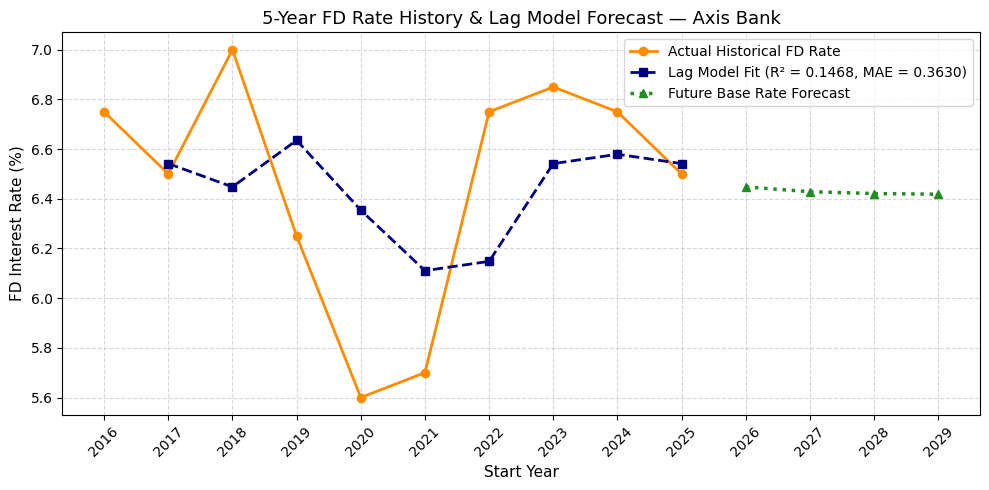

In [5]:
import matplotlib.pyplot as plt

# 1. Historical Actual vs. Lag Model Predicted Rates
hist_years = lag_df['Start_Year'].values
hist_actual = lag_df[rate_col].values

# 2. Reconstruct future forecast points for plotting
future_years = []
future_rates = []
temp_last_rate = float(bank_data[rate_col].iloc[-1])
latest_year = int(bank_data['Start_Year'].max())

for year_idx in range(1, simulation_years + 1):
    future_years.append(latest_year + year_idx)
    pred = max(0.0, float(lag_model.predict(np.array([[temp_last_rate]]))[0]))
    future_rates.append(pred)
    temp_last_rate = pred

# 3. Plot Actual, Historical Lag Fit, and Future Forecast
plt.figure(figsize=(10, 5))
plt.plot(bank_data['Start_Year'], bank_data[rate_col], marker='o', color='darkorange', linewidth=2, label='Actual Historical FD Rate')
plt.plot(hist_years, y_pred_lag, marker='s', linestyle='--', color='navy', linewidth=2, label=f'Lag Model Fit (R² = {r2:.4f}, MAE = {mae:.4f})')
plt.plot(future_years, future_rates, marker='^', linestyle=':', color='forestgreen', linewidth=2.5, label='Future Base Rate Forecast')

plt.title(f'5-Year FD Rate History & Lag Model Forecast — {target_bank}', fontsize=13)
plt.xlabel('Start Year', fontsize=11)
plt.ylabel('FD Interest Rate (%)', fontsize=11)
plt.xticks(list(bank_data['Start_Year']) + future_years, rotation=45)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()
plt.tight_layout()
plt.show()